In [14]:
import numpy as np
import tensorflow as tf
import keras
from keras import layers, models
import matplotlib.pyplot as plt
import seaborn as sns

In [15]:
# Label 0 = Nature / Sports / Fruit context
# Label 1 = Finance / Animal / Tech context
sentences = [
    # "bank"
    "he sat by the river bank and watched the water",
    "the boat pulled up to the muddy river bank",
    "water overflowed the steep river bank after heavy rain",
    "she went to the bank to deposit her money",
    "the bank approved his loan and opened an account",
    "he withdrew cash from the bank near the office",
    # "bat"
    "he swung the wooden bat and hit the ball",
    "the player picked up his cricket bat before batting",
    "she bought a new baseball bat for the match",
    "a nocturnal bat flew out of the dark cave",
    "the small bat hung upside down in the cave",
    "a flying bat uses echoes to hunt at night",
    # "apple"
    "she ate a sweet red apple for breakfast",
    "the fresh green apple fell from the orchard tree",
    "he sliced the juicy apple into small pieces",
    "she bought a new apple laptop and phone",
    "the apple device runs fast software and apps",
    "he updated his apple computer at the desk"
]
labels = np.array([0, 0, 0, 1, 1, 1] * 3)

In [22]:
MAX_LEN = 12
VOCAB_SIZE = 100
EMBED_DIM = 32

vectorizer = layers.TextVectorization(
    max_tokens=VOCAB_SIZE,
    output_mode="int",
    output_sequence_length=MAX_LEN
)
vectorizer.adapt(sentences)
vocab = vectorizer.get_vocabulary()

class TokenAndPositionEmbedding(layers.Layer):
    def __init__(self, maxlen, vocab_size, embed_dim):
        super().__init__()
        self.token_emb = layers.Embedding(input_dim=vocab_size, output_dim=embed_dim)
        self.pos_emb = layers.Embedding(input_dim=maxlen, output_dim=embed_dim)

    def call(self, x):
        maxlen = tf.shape(x)[-1]
        positions = tf.range(start=0, limit=maxlen, delta=1)
        return self.token_emb(x) + self.pos_emb(positions)


In [17]:
inputs = layers.Input(shape=(MAX_LEN,), dtype=tf.int32)
x_embed = TokenAndPositionEmbedding(MAX_LEN, VOCAB_SIZE, EMBED_DIM)(inputs)

# Self-Attention: query=x_embed, value=x_embed, key=x_embed
mha_layer = layers.MultiHeadAttention(num_heads=2, key_dim=16, name="self_attention")
attn_output, attn_scores = mha_layer(
    query=x_embed,
    value=x_embed,
    return_attention_scores=True
)

# Residual Connection + LayerNorm (Standard Transformer Encoder step)
x_contextual = layers.LayerNormalization(epsilon=1e-6)(x_embed + attn_output)

# Classification head to force the model to learn context
pooled = layers.GlobalAveragePooling1D()(x_contextual)
outputs = layers.Dense(1, activation="sigmoid")(pooled)

model = models.Model(inputs=inputs, outputs=outputs)
model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.01),
              loss="binary_crossentropy",
              metrics=["accuracy"])

# Train on tokenized sentences
X_tokens = vectorizer(sentences)
model.fit(X_tokens, labels, epochs=60, verbose=0)

In [18]:
inspector = tf.keras.Model(
    inputs=model.input,
    outputs=[x_embed, x_contextual, attn_scores]
)

test_sentences = [
    "he sat by the river bank and watched the water",
    "she went to the bank to deposit her money"
]
test_tokens = vectorizer(test_sentences)
static_emb, contextual_emb, scores = inspector.predict(test_tokens, verbose=0)

In [23]:
# Helper to compute cosine similarity
def cosine_sim(a, b):
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))

# Find token index of "bank" in both sentences
tokens_s0 = [vocab[idx] for idx in test_tokens[0].numpy() if idx != 0]

tokens_s1 = [vocab[idx] for idx in test_tokens[1].numpy() if idx != 0]

pos_s0 = tokens_s0.index("bank")
pos_s1 = tokens_s1.index("bank")

# Compare "bank" vectors BEFORE vs AFTER Self-Attention
token_layer = model.layers[1].token_emb
bank_id = vocab.index("bank")
bank_vector = token_layer(tf.constant([bank_id]))[0].numpy()

pure_static_sim = cosine_sim(bank_vector, bank_vector)
post_attn_sim = cosine_sim(contextual_emb[0, pos_s0], contextual_emb[1, pos_s1])

print(f"Cosine Similarity of 'bank' BEFORE Self-Attention: {pure_static_sim:.4f}")
print(f"Cosine Similarity of 'bank' AFTER Self-Attention:  {post_attn_sim:.4f}")

Cosine Similarity of 'bank' BEFORE Self-Attention: 1.0000
Cosine Similarity of 'bank' AFTER Self-Attention:  -0.9361


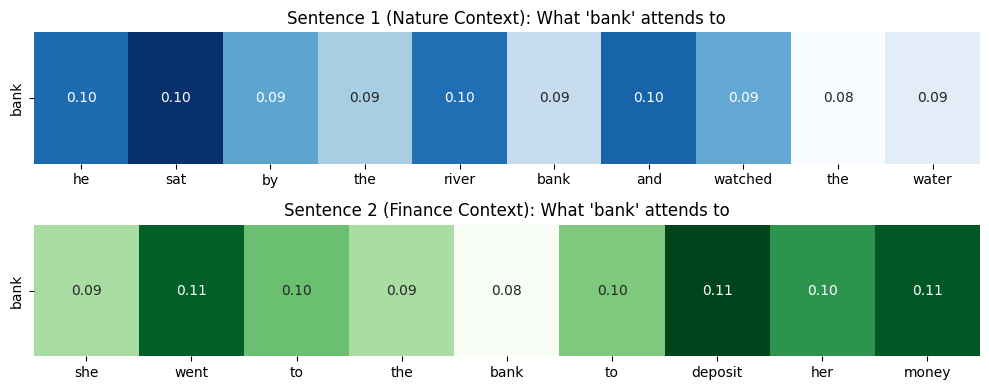

In [24]:
# Average attention scores across the 2 heads: shape -> (seq_len, seq_len)
attn_s0 = scores[0].mean(axis=0)[pos_s0, :len(tokens_s0)]
attn_s1 = scores[1].mean(axis=0)[pos_s1, :len(tokens_s1)]

fig, axes = plt.subplots(2, 1, figsize=(10, 4))

sns.heatmap([attn_s0], xticklabels=tokens_s0, yticklabels=["bank"],
            cmap="Blues", annot=True, fmt=".2f", ax=axes[0], cbar=False)
axes[0].set_title("Sentence 1 (Nature Context): What 'bank' attends to")

sns.heatmap([attn_s1], xticklabels=tokens_s1, yticklabels=["bank"],
            cmap="Greens", annot=True, fmt=".2f", ax=axes[1], cbar=False)
axes[1].set_title("Sentence 2 (Finance Context): What 'bank' attends to")

plt.tight_layout()
plt.show()

`Bank` in Sentence 1 focuses more on the River and sat.
Where `bank` in Sentence 2 focuses on the money, deposit